# 중마시장 | 독립 근린형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, HOUR, WEEK, STAY, CASE_COMPARISONS, STAY_CASES, TIME_FIGURES,
                      plot_case_comparison, plot_stay_case, plot_time_weekday)
CASE = '중마시장'


## 이동·체류와 비교 기준

* 정류장·주차장: 저장된 공개 요약값
* 시설 위치: 이 노트북에서 재집계하지 않음

,지표,비교 대상,값,단위
0,쇼핑 OD 출발지 10km 안,중마,89.6,%
1,쇼핑 OD 출발지 10km 안,전국 평균,70.7,%
2,귀가 목적 도착 OD,중마,62.4,%
3,귀가 목적 도착 OD,전국 평균,55.7,%
4,반경 500m 버스정류장,중마,41.0,곳
5,반경 500m 버스정류장,전국 평균,19.9,곳
6,반경 500m 공영주차장,중마,11.0,곳
7,반경 500m 공영주차장,전국 평균,5.3,곳


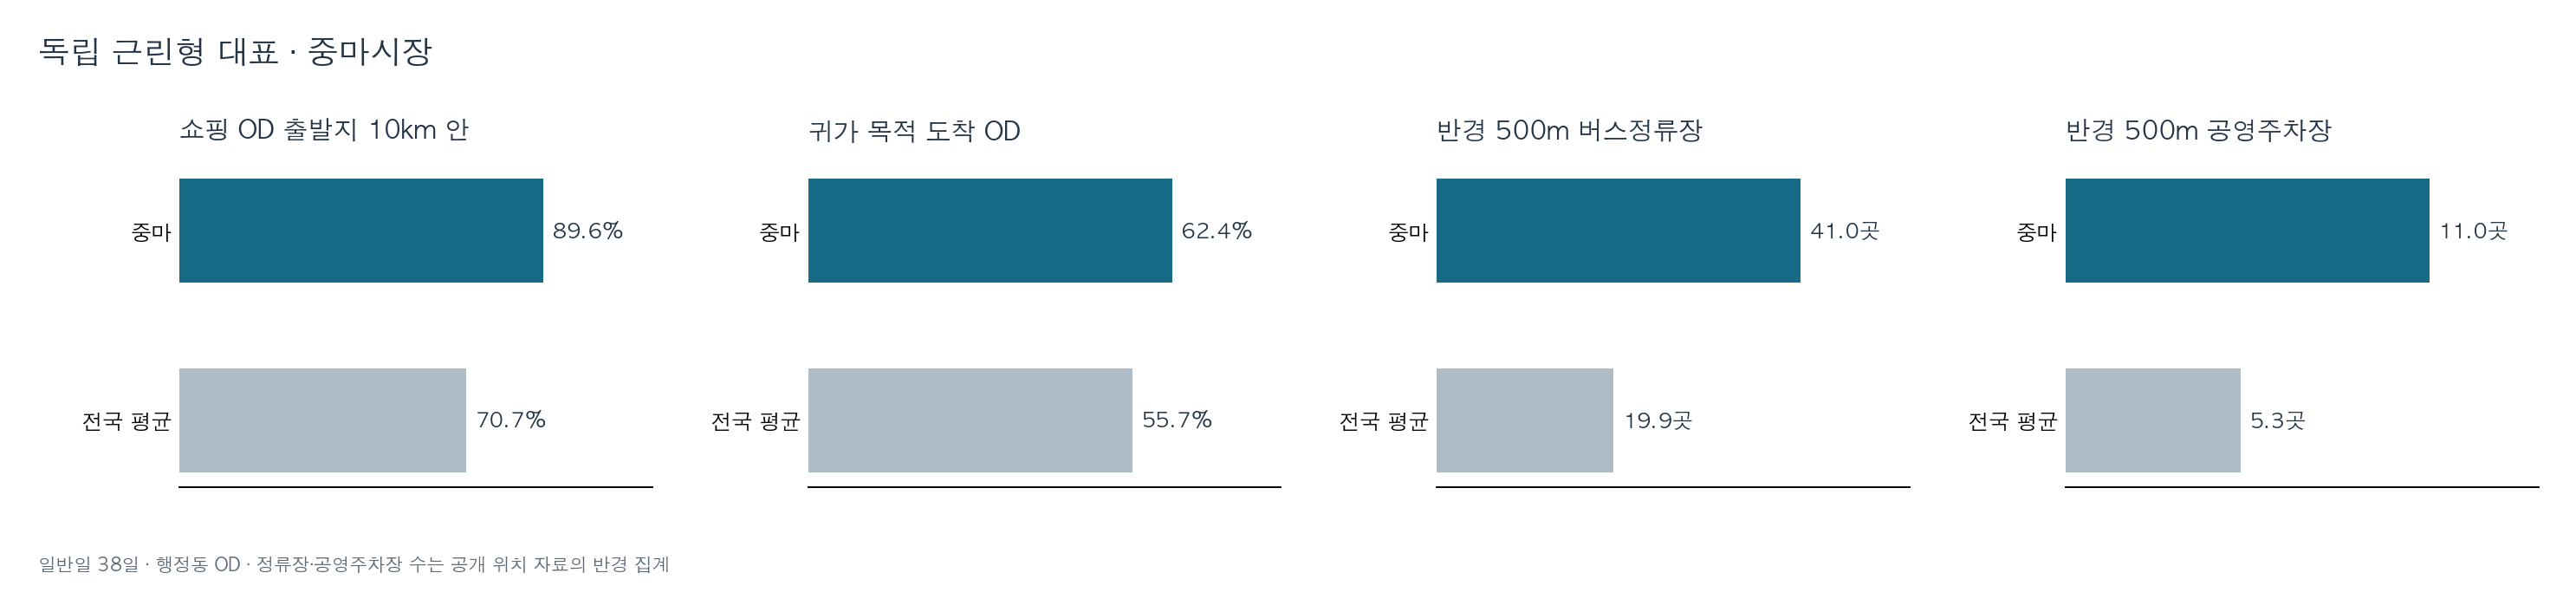

In [2]:
filename, title, panels, note = CASE_COMPARISONS[CASE]
comparison = pd.DataFrame([
    {"지표": metric, "비교 대상": name, "값": value, "단위": unit}
    for metric, names, values, unit in panels
    for name, value in zip(names, values)
])
display(comparison)
plot_case_comparison(CASE)
display(Image(filename=str(FIGS / filename)))

## 체류 구성

In [ ]:
stay = STAY
selected = stay.loc[stay["case"].eq(CASE),
                    ["metric", "case_share", "national_market_row_mean", "scope"]].copy()
selected[["case_share", "national_market_row_mean"]] *= 100
display(selected.rename(columns={"case_share":"사례 (%)",
                                  "national_market_row_mean":"전국 시장 행 평균 (%)"}))
plot_stay_case(CASE)
display(Image(filename=str(FIGS / STAY_CASES[CASE][0])))

## 시간·요일별 분포

,measure,daytype,정점 시각,시간별 구성비 (%)
193,귀가 목적 도착 OD,주말,17,14.6
209,귀가 목적 도착 OD,평일,17,27.2
229,체류 STAY 전체,주말,21,6.7
243,체류 STAY 전체,평일,19,7.1


,measure,day_of_week,요일별 구성비 (%),observed_days
42,귀가 목적 도착 OD,0,15.6,4
43,귀가 목적 도착 OD,1,16.5,5
44,귀가 목적 도착 OD,2,15.5,6
45,귀가 목적 도착 OD,3,15.8,5
46,귀가 목적 도착 OD,4,14.9,6
47,귀가 목적 도착 OD,5,10.4,6
48,귀가 목적 도착 OD,6,11.2,6
49,체류 STAY 전체,0,14.5,4
50,체류 STAY 전체,1,14.4,5
51,체류 STAY 전체,2,14.5,6


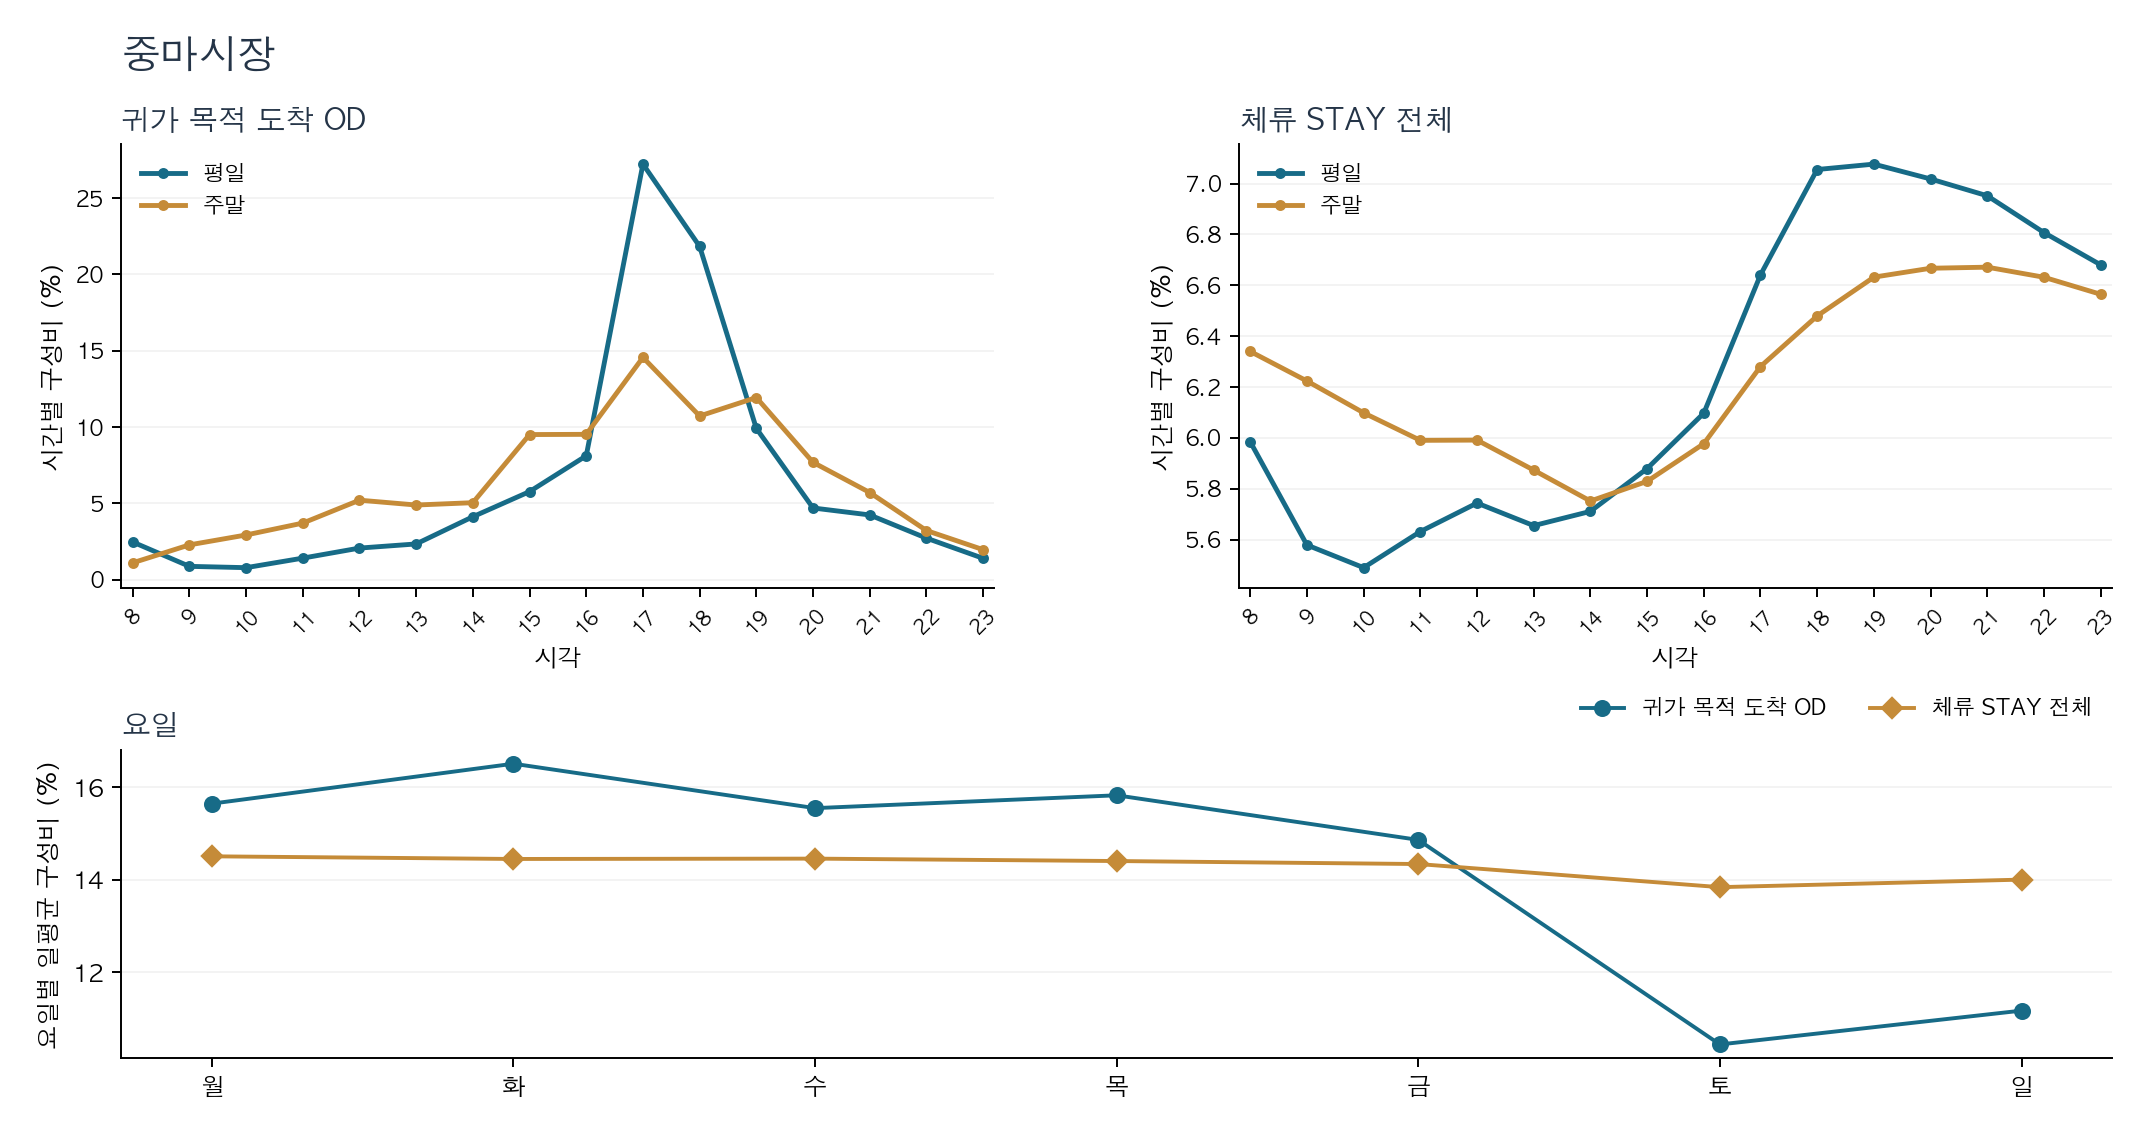

In [4]:
hourly = HOUR.loc[HOUR["case"].eq(CASE)].copy()
peaks = hourly.loc[hourly.groupby(["measure", "daytype"])["hour_share"].idxmax(),
                   ["measure", "daytype", "hour", "hour_share"]].copy()
peaks["hour_share"] = (peaks["hour_share"] * 100).round(1)
display(peaks.rename(columns={"hour":"정점 시각", "hour_share":"시간별 구성비 (%)"}))
weekday = WEEK.loc[WEEK["case"].eq(CASE)].copy()
weekday["요일별 구성비 (%)"] = weekday.groupby("measure")["daily_index"].transform(
    lambda values: values / values.sum() * 100
).round(1)
display(weekday[["measure", "day_of_week", "요일별 구성비 (%)", "observed_days"]])
plot_time_weekday(CASE)
display(Image(filename=str(FIGS / TIME_FIGURES[CASE])))

## 제안

* 방안: 귀가 동선의 짧은 물품 수령을 소규모로 시험
* 상태: 시행·효과 미확인